# CasaHarvest — modules 1 et 2 : de l'eau à la récolte

**Région** : Casablanca-Settat, 4 zones (Settat-Berrechid, El Jadida-Sidi Bennour, Benslimane, préfectures de Casablanca), **depuis 2010**.

| Module | Question | Données | Modèles |
|---|---|---|---|
| 1. Rendement agricole | Quel rendement de céréales cette année ? | Rendements HCP par province (FEWS NET), 2010-2023 ; pluie CHIRPS ; humidité du sol ERA5-Land | Ridge, XGBoost, hybride |
| 2. Risque de sécheresse | Y aura-t-il une sécheresse le mois prochain ? | Indice SPI mensuel (CHIRPS), humidité du sol, 2010-2026 | Ridge, XGBoost |

Les résultats sont calculés par `run_casaharvest.py` et lus ici dans `resultats/`.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 2); pd.set_option("display.width", 200)
R = Path("resultats")

## Module 1 — Prévision du rendement des céréales

**Cible** : rendement (q/ha) du blé tendre, du blé dur et de l'orge, par zone et par campagne (167 observations : 4 zones × 14 campagnes × 3 cultures).

**Deux moments de prévision** :
- **fin mars** (prévision précoce) : SPI-6 de mars (sécheresse des 6 derniers mois) + humidité du sol en hiver ;
- **fin mai** (fin de campagne) : SPI-6 de mars + humidité du sol au printemps + nombre de jours ≥ 30 °C au printemps.

**Choix des variables** : avec seulement 14 campagnes, un jeu réduit est plus stable. Le SPI-6 de mars seul explique déjà l'essentiel (R² ≈ 0,47 avec XGBoost) ; les cumuls de pluie sont redondants avec lui.

**Évaluation** : validation croisée *une campagne laissée de côté* — toutes les zones d'une même année sont mises de côté ensemble (elles partagent la même météo ; sinon l'évaluation serait trop optimiste).

Précision (validation croisée, toutes zones et cultures) :


MAE_qx_ha  RMSE_qx_ha    R2      n
moment modele                                                                 
mai    Hybride (XGBoost + garde-fou Ridge)       6.50        8.32  0.43  167.0
       Ridge                                     6.93        8.72  0.37  167.0
       XGBoost                                   6.30        7.97  0.47  167.0
mars   Hybride (XGBoost + garde-fou Ridge)       6.37        8.54  0.40  167.0
       Ridge                                     6.90        8.94  0.34  167.0
       XGBoost                                   6.25        8.11  0.46  167.0

Au niveau de la région (rendement moyen pondéré par les surfaces) :


MAE_qx_ha  RMSE_qx_ha    R2     n
moment modele                                                                
mai    Hybride (XGBoost + garde-fou Ridge)       6.11        7.80  0.45  42.0
       Ridge                                     6.41        8.45  0.35  42.0
       XGBoost                                   5.78        7.25  0.52  42.0
mars   Hybride (XGBoost + garde-fou Ridge)       5.79        8.00  0.42  42.0
       Ridge                                     6.12        8.89  0.28  42.0
       XGBoost                                   5.65        7.45  0.49  42.0

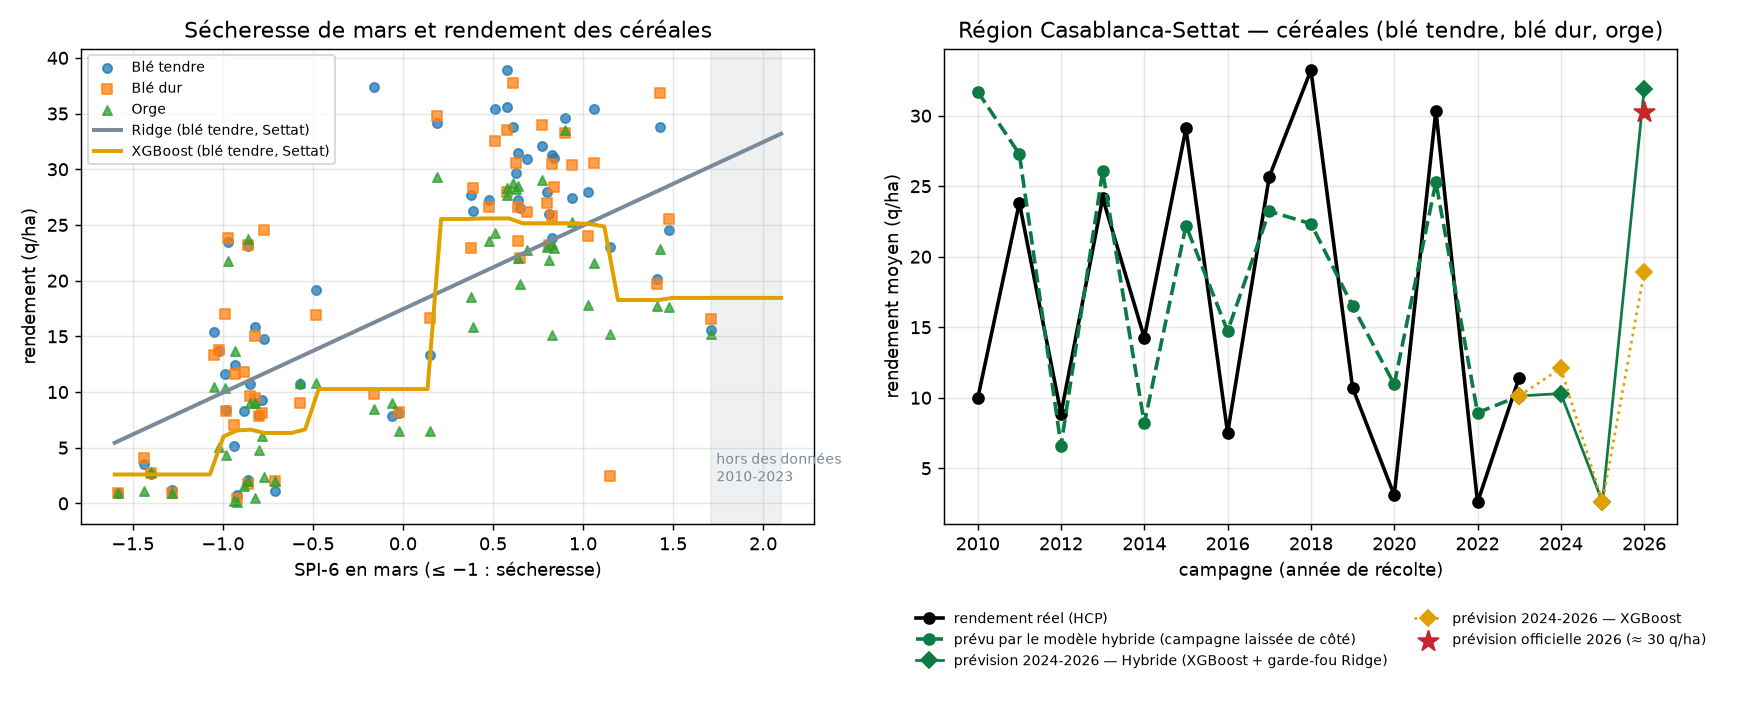

In [2]:
print("Précision (validation croisée, toutes zones et cultures) :")
display(pd.read_csv(R / "m1_metriques.csv", index_col=[0, 1]))
print("Au niveau de la région (rendement moyen pondéré par les surfaces) :")
display(pd.read_csv(R / "m1_metriques_region.csv", index_col=[0, 1]))
display(Image(R / "fig_m1_rendement.png"))

**Lecture**

- La **sécheresse de mars (SPI-6)** est le facteur dominant : quand il est sous −1, le rendement s'effondre (souvent < 10 q/ha) ; au-dessus de 0, il dépasse en général 20 q/ha.
- **XGBoost** capte mieux cette relation en « marche d'escalier » que la Ridge linéaire (R² 0,47 contre 0,37, erreur moyenne ±6,3 q/ha).
- Mais **XGBoost ne sait pas extrapoler** : en 2026, le SPI-6 de mars atteint **+1,91** en moyenne sur la région, plus humide que toutes les années 2010-2023 (maximum régional +1,44, zone grisée sur la figure). XGBoost répète alors ce qu'il a vu pour l'année la plus humide connue et prévoit 18,9 q/ha.
- D'où le **modèle hybride** : XGBoost quand le climat ressemble au passé, Ridge (qui prolonge la tendance) quand une variable sort de la plage observée. En validation croisée, il est un peu moins précis que XGBoost (R² 0,43), mais il est robuste aux années exceptionnelles.
- Cas particulier : **2010** était très humide mais avec un rendement moyen (≈ 10 q/ha) ; l'excès d'eau peut aussi nuire aux cultures, ce que le modèle ne capte pas.

In [3]:
print("Prévisions des campagnes sans rendement publié (fin mai) :")
display(pd.read_csv(R / "m1_previsions_region_2024_2026.csv", header=[0, 1], index_col=0))

Prévisions des campagnes sans rendement publié (fin mai) :


rendement_moyen_qx_ha                                    production_Mqx               
modele   Hybride (XGBoost + garde-fou Ridge) Ridge XGBoost Hybride (XGBoost + garde-fou Ridge)  Ridge XGBoost
campagne                                                                                                     
2024                                    10.3   8.5    12.1                                8.47   7.03   10.02
2025                                     2.6   8.3     2.6                                2.15   6.89    2.15
2026                                    31.9  31.9    18.9                               26.33  26.33   15.61

**Contrôle externe (campagne 2026)** : la Direction régionale de l'agriculture annonce environ **25,8 millions de quintaux** de céréales pour Casablanca-Settat (≈ 30 q/ha sur 852 555 ha). Le modèle hybride prévoit **26,3 millions de quintaux (31,9 q/ha)** — un écart d'environ 2 % ; XGBoost seul aurait prévu 15,6 Mqx.

*Limites* : 2024 et 2025 n'ont pas pu être vérifiées (pas de bilan régional publié trouvé) ; au niveau national, 2025 a été meilleure que 2024 (≈ 44 contre 31 Mqx), alors que le modèle prévoit l'inverse pour la région — la pluie tardive de mars 2025 est peut-être mal captée. La production prévue utilise la surface moyenne des 3 dernières campagnes connues.

## Module 2 — Prévision du risque de sécheresse

**Cible** : SPI-3 du mois suivant (h = 1, 2, 3 mois), par zone. SPI ≤ −1 : sécheresse modérée ; ≤ −1,5 : sévère ; ≤ −2 : extrême.
**Variables** (connues au mois t) : SPI-1, SPI-3, SPI-6, SPI-12, anomalie d'humidité du sol, mois visé, zone.
**Saison** : mois visés d'octobre à mai uniquement (en été il ne pleut presque pas, le SPI n'a pas de sens).
**Évaluation** : validation temporelle à fenêtre croissante — chaque année de 2018 à 2026 est prévue avec un modèle entraîné sur les années précédentes seulement.
**Alerte** : la régression ramène les prévisions vers la normale ; on déclenche une alerte dès que le SPI-3 prévu est ≤ −0,5 (seuil choisi sur la validation).

RMSE    R2  correlation  AUC_secheresse  secheresses_detectees_pct  fausses_alertes_pct      n  mois_en_secheresse
horizon modele                                                                                                                     
1       Ridge    0.63  0.63         0.81            0.89                      76.19                41.46  276.0                63.0
        XGBoost  0.71  0.53         0.73            0.83                      74.60                48.35  276.0                63.0
2       Ridge    0.89  0.26         0.52            0.74                      55.56                42.62  276.0                63.0
        XGBoost  0.97  0.12         0.40            0.72                      34.92                55.10  276.0                63.0
3       Ridge    1.11 -0.16        -0.04            0.55                       0.00               100.00  276.0                63.0
        XGBoost  1.23 -0.43        -0.26            0.48                       9.52                77.78  276.0                63.0

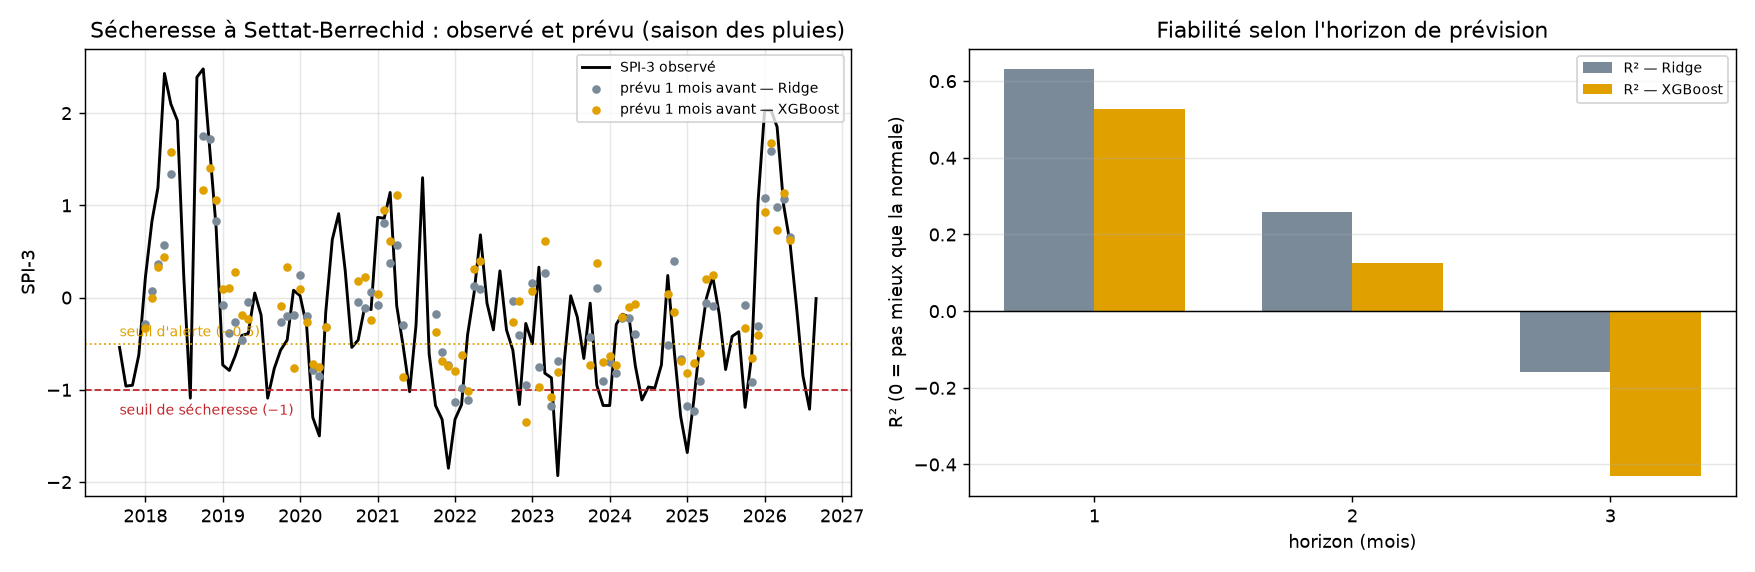

In [4]:
display(pd.read_csv(R / "m2_metriques.csv", index_col=[0, 1]))
display(Image(R / "fig_m2_secheresse.png"))

**Lecture**

- **À 1 mois**, la prévision est fiable : R² 0,63, et le système d'alerte repère **76 % des sécheresses** à l'avance (41 % de fausses alertes). C'est en partie mécanique : le SPI-3 du mois prochain contient déjà 2 mois de pluie connus.
- **À 2 mois**, la fiabilité est faible (R² 0,26) ; **à 3 mois**, le modèle ne fait pas mieux que la normale (R² négatif) : la pluie au Maroc est imprévisible au-delà de quelques semaines à partir des seules observations locales.
- La **Ridge** est meilleure que XGBoost ici : la relation est essentiellement linéaire (persistance) et les données sont peu nombreuses.

In [5]:
print("Situation actuelle (dernier mois connu) :")
display(pd.read_csv(R / "m2_etat_actuel.csv"))
print("Prévision des 3 prochains mois (Ridge) :")
display(pd.read_csv(R / "m2_prevision_3_mois.csv"))

Situation actuelle (dernier mois connu) :


,zone,mois,spi_1,spi_3,spi_6,spi_12,anomalie_humidite_sol,classe_secheresse_spi3
0,Casablanca (préfectures),2026-09,-0.22,-0.22,-0.41,1.70,-0.07,normal
1,Benslimane,2026-09,-0.12,-0.08,-0.53,1.91,0.00,normal
2,El Jadida-Sidi Bennour,2026-09,-0.37,-0.43,-0.57,1.69,1.27,normal
3,Settat-Berrechid,2026-09,-0.00,-0.01,-0.14,1.79,-0.70,normal


Prévision des 3 prochains mois (Ridge) :


,zone,dernier_mois_connu,mois_prevu,horizon_mois,spi3_prevu,classe,alerte_secheresse,fiabilite
0,Benslimane,2026-09,2026-10,1,-0.14,normal,non,bonne
1,Casablanca (préfectures),2026-09,2026-10,1,-0.21,normal,non,bonne
2,El Jadida-Sidi Bennour,2026-09,2026-10,1,-0.22,normal,non,bonne
3,Settat-Berrechid,2026-09,2026-10,1,-0.10,normal,non,bonne
4,Benslimane,2026-09,2026-11,2,-0.41,normal,non,faible
5,Casablanca (préfectures),2026-09,2026-11,2,-0.37,normal,non,faible
6,El Jadida-Sidi Bennour,2026-09,2026-11,2,-0.44,normal,non,faible
7,Settat-Berrechid,2026-09,2026-11,2,-0.23,normal,non,faible
8,Benslimane,2026-09,2026-12,3,-0.43,normal,non,très faible (indicatif)
9,Casablanca (préfectures),2026-09,2026-12,3,-0.35,normal,non,très faible (indicatif)


## Conclusions et lien avec le module 3 (prix)

1. **Eau → récolte** : la sécheresse de fin d'hiver (SPI-6 de mars) explique environ la moitié des variations de rendement des céréales dans la région. Le modèle hybride donne une prévision dès **fin mars**, trois mois avant la récolte, et a reproduit à 2 % près la prévision officielle 2026.
2. **Sécheresse** : une alerte fiable est possible **un mois à l'avance** ; au-delà, il faudrait des prévisions saisonnières météorologiques (non disponibles en données ouvertes ici).
3. **Récolte → marché** : les céréales et les fruits et légumes du module 3 ne réagissent pas de la même façon ; le lien entre rendement céréalier et prix des légumes à Casablanca est indirect et à présenter avec prudence.
4. **Limites** : 14 campagnes seulement ; SPI calibré sur 17 ans (30 ans recommandés) ; rendements 2024-2026 non encore publiés.